# Checking the Growth Metrics of a Subscription Service — MRR Analysis Practice

Let's run the MRR analysis covered in the chapter ourselves. The subscription data you can download
differs a bit from store to store, but the analytical frame — decomposing MRR and examining GRR and
NRR — works regardless of which store you use. Using a single payment log shaped like a
Google Play Sales Report, we reproduce the pipeline from start to finish.

- **6.3.2.** Identify users from `order_number` (6.2.4.1)
- **6.3.3.** Separate renew from reactivation (6.2.4.3)
- **6.3.4.** Decompose monthly MRR into new / renew / reactivation / expansion / contraction / churn (6.2.3, 6.2.4.2)
- **6.3.5.** Diagnose revenue retention with GRR and NRR (6.2.4.6)
- **6.3.6.** Recover the answer planted in the data (5% monthly churn) and connect it to the LTV rule of thumb.

Verification and deep-dive sections that appear only in the notebook, not in the book, are marked
**[Notebook extra]** (checking payment intervals, verifying the MRR identity, decomposing subscriber
counts — 6.2.4.7). Trial flows, prorating annual subscriptions (retained MRR), and refund handling are
covered in the book's narrative and are not part of this practice.


## 6.3.1. Preparing the practice data

The two cells below install the dependencies and import the libraries. If you don't have the data
yet, first run `python generate_data.py` in a terminal to create the example data
(`data/subscription_sales.csv`). Then set up the notebook environment and start the practice.


In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Create one in-memory DuckDB connection and reuse it throughout the notebook.
con = duckdb.connect()
con.execute("CREATE TABLE sales AS "
            "SELECT * FROM read_csv_auto('data/subscription_sales.csv')")

### A look at the payment log

The practice uses just one table. It is a payment log shaped like Google Play's Sales Report,
holding 10,653 payment records that occurred over 18 months. There is no column that identifies the
user; instead, we assume the order number lets us tell the order of payments apart. The first payment
has no suffix on `order_number`, and renewal payments carry `..1`, `..2`, and so on. There are two
products: basic at 4,900 KRW per month and plus at 9,900 KRW per month.


In [4]:
display(con.execute("SELECT count(*) AS rows, min(order_charged_date) AS first, "
                    "max(order_charged_date) AS last FROM sales").df())
con.execute("SELECT * FROM sales ORDER BY order_charged_date LIMIT 5").df()

,rows,first,last
0,10653,2025-01-01,2026-06-28


,order_number,order_charged_date,product_id,sales_amount_krw
0,GPA.3473-2940-6316-10023,2025-01-01,monthly_basic,4900
1,GPA.4592-1953-7554-10053,2025-01-02,monthly_basic,4900
2,GPA.7136-4072-6031-10032,2025-01-02,monthly_basic,4900
3,GPA.9603-9106-3123-10049,2025-01-02,monthly_basic,4900
4,GPA.5376-7591-3453-10048,2025-01-03,monthly_plus,9900


## 6.3.2. Identifying users from order_number

Every analysis starts by grouping payments by user. We assume that orders sharing the same prefix
(the part before `'..'`) belong to the same user. The suffix can show up as 0, 1, null, and other
variants, so rather than trusting it, it is safer to count the cumulative payment number
(`order_cnt`) ourselves with `row_number()` ordered by payment date.

The following steps keep reusing this user identification, so we save it as the orders view.


In [5]:
con.execute("""
    CREATE OR REPLACE VIEW orders AS
    SELECT
        split_part(order_number, '..', 1)  AS pid
      , order_charged_date
      , product_id
      , sales_amount_krw
      , row_number() OVER (PARTITION BY split_part(order_number, '..', 1)
                           ORDER BY order_charged_date) AS order_cnt
    FROM sales
""")
orders = con.execute("SELECT * FROM orders").df()
n_orders = orders.groupby("pid").size()
print(f"Users: {orders.pid.nunique():,} / Payments: {len(orders):,}")
print(f"Payments per user: min {n_orders.min()} ~ max {n_orders.max()}")
n_orders.value_counts().sort_index()

Users: 1,653 / Payments: 10,653
Payments per user: min 1 ~ max 18


1     198
2     179
3     169
4     149
5     134
6     126
7     114
8      93
9      85
10     72
11     75
12     62
13     45
14     41
15     35
16     29
17     22
18     25
Name: count, dtype: int64

## 6.3.3. Separating renew from reactivation

In 6.2.4.3 we said it is best to distinguish a consecutive repeat payment (renew) from a repeat
payment after a gap (reactivation). We fetch the previous payment date with `LAG()` and classify
the payment as renew if the interval is under 32 days (one cycle of roughly 30 days plus some slack),
and as reactivation otherwise. Saving the result as the classified view lets the MRR decomposition
query in 6.3.4 pick it up as is.

> **[Applying to your data]** If your billing cycle is not monthly, change the 32-day threshold to match the cycle.
> This approach does not suit products with long cycles such as annual subscriptions; see 6.2.4.4.


In [6]:
con.execute("""
    CREATE OR REPLACE VIEW classified AS
    SELECT *
         , CASE WHEN order_cnt = 1 THEN 'new'
                WHEN order_charged_date - prev_date < 32
                     THEN 'renew'
                ELSE 'reactivation' END AS pay_type
    FROM (SELECT *
               , lag(order_charged_date) OVER (
                     PARTITION BY pid ORDER BY order_charged_date) AS prev_date
          FROM orders)
""")
classified = con.execute("SELECT * FROM classified").df()
classified.pay_type.value_counts()

pay_type
renew           8961
new             1653
reactivation      39
Name: count, dtype: int64

### [Notebook extra] Verifying the classification with payment intervals

Let's check that the classification worked by looking at the distribution of payment intervals.
renew should cluster at 28–31 days (a monthly cycle), and reactivation should appear only after a gap of at least a month.


In [7]:
gap = (pd.to_datetime(classified.order_charged_date)
       - pd.to_datetime(classified.prev_date)).dt.days
for t in ["renew", "reactivation"]:
    g = gap[classified.pay_type == t]
    print(f"{t:14s} interval: {g.min():.0f} ~ {g.max():.0f} days (median {g.median():.0f} days)")

renew          interval: 28 ~ 31 days (median 31 days)
reactivation   interval: 44 ~ 396 days (median 160 days)


## 6.3.4. Decomposing monthly MRR

Once we aggregate payments per user × month and **FULL OUTER JOIN** them with the previous month,
every user falls into one of three states.

- Paid both this month and last month → continuing subscriber (any increase in the repeat payment is expansion, any decrease is contraction, and the part that stayed is renew: the renew MRR from 6.2.3 minus contraction)
- Paid this month only → new or reactivation
- Paid last month only → churn

Here renew is the "amount kept as is": the renew MRR from 6.2.3 (previous-month MRR − churn MRR)
with contraction subtracted as well. Because the downgraded portion has already been removed, in this
practice's result table MRR = renew + new + reactivation + expansion holds exactly. To match the
formula in 6.2.3, add contraction back onto renew.

The same query is also provided as the file `sql/mrr_breakdown.sql`.


First we build the user × month aggregate as the monthly view.


In [8]:
con.execute("""
    CREATE OR REPLACE VIEW monthly AS
    -- User x month aggregate: collapse multiple payments in the same month (e.g. a mid-month plan change) into one row
    SELECT
        pid
      , date_trunc('month', order_charged_date) AS month
      , sum(sales_amount_krw) AS amt
      -- pay_type priority: new > reactivation > renew (happens to match alphabetical order)
      , min(pay_type) AS pay_type
    FROM classified
    GROUP BY pid, month
""")

Next we join the monthly view to itself, offset by one month, to build the paired view that pairs this month (c) with the previous month (p).


In [9]:
con.execute("""
    CREATE OR REPLACE VIEW paired AS
    SELECT
        coalesce(c.month, p.month + INTERVAL 1 MONTH) AS month
      , c.amt AS amt             -- this month's payment (NULL = churned)
      , p.amt AS prev_amt        -- previous month's payment (NULL = new/returning)
      , c.amt - p.amt AS delta   -- change (used for expansion/contraction)
      , c.pay_type
      , c.amt IS NOT NULL AND p.amt IS NOT NULL AS stayed  -- paid in both months
    FROM monthly c
    FULL OUTER JOIN monthly p
      ON c.pid = p.pid AND p.month = c.month - INTERVAL 1 MONTH
""")

Now aggregating the paired view yields all six MRR components at once. The "paid in both months" condition, which would otherwise be repeated three times, collapses into the single stayed flag.

In [10]:
mrr = con.execute("""
    SELECT
        month
      , sum(amt)                                            AS mrr
      , sum(CASE pay_type WHEN 'new' THEN amt END)          AS new_mrr
      , sum(CASE pay_type WHEN 'reactivation' THEN amt END) AS reactivation_mrr
      , sum(CASE WHEN stayed THEN least(amt, prev_amt) END) AS renew_mrr
      , sum(CASE WHEN stayed THEN greatest(delta, 0) END)   AS expansion_mrr
      , sum(CASE WHEN stayed THEN greatest(-delta, 0) END)  AS contraction_mrr
      , sum(CASE WHEN amt IS NULL THEN prev_amt END)        AS churn_mrr
      , sum(prev_amt)                                       AS baseline_mrr
    FROM paired
    -- Drop the 'ghost month' that appears after the last month (rows with only a previous month)
    WHERE month <= (SELECT max(month) FROM monthly)
    GROUP BY month
    ORDER BY month
""").df().fillna(0)
mrr["month"] = pd.to_datetime(mrr["month"]).dt.to_period("M").astype(str)
mrr = mrr.iloc[1:].reset_index(drop=True)  # the first month has no previous month, so drop it
mrr.tail(6)

,month,mrr,new_mrr,reactivation_mrr,renew_mrr,expansion_mrr,contraction_mrr,churn_mrr,baseline_mrr
11,2026-01,5039000.0,659100.0,44500.0,4285400.0,50000.0,10000.0,196800.0,4492200.0
12,2026-02,5680800.0,783500.0,14700.0,4797600.0,85000.0,5000.0,236400.0,5039000.0
13,2026-03,6108800.0,753000.0,29500.0,5301300.0,25000.0,5000.0,374500.0,5680800.0
14,2026-04,6561000.0,712800.0,34400.0,5783800.0,30000.0,20000.0,305000.0,6108800.0
15,2026-05,7136700.0,747000.0,29500.0,6270200.0,90000.0,25000.0,265800.0,6561000.0
16,2026-06,7608900.0,811700.0,49300.0,6707900.0,40000.0,25000.0,403800.0,7136700.0


### [Notebook extra] Verifying the MRR identity

Let's confirm that the formula from 6.2.3 actually holds.

**MRR = previous-month MRR (Baseline) + new + reactivation + expansion − contraction − churn**

The practice's renew is the retained amount with contraction removed, but this formula starts from
the Baseline rather than renew, so it holds as is.


In [11]:
check = (mrr.baseline_mrr + mrr.new_mrr + mrr.reactivation_mrr
         + mrr.expansion_mrr - mrr.contraction_mrr - mrr.churn_mrr)
print("Max identity error:", (mrr.mrr - check).abs().max(), "KRW")

Max identity error: 0.0 KRW


Using the table above, let's break MRR down in a chart. We stack expansion, reactivation, and new on top of renew, and show churn as a negative bar.


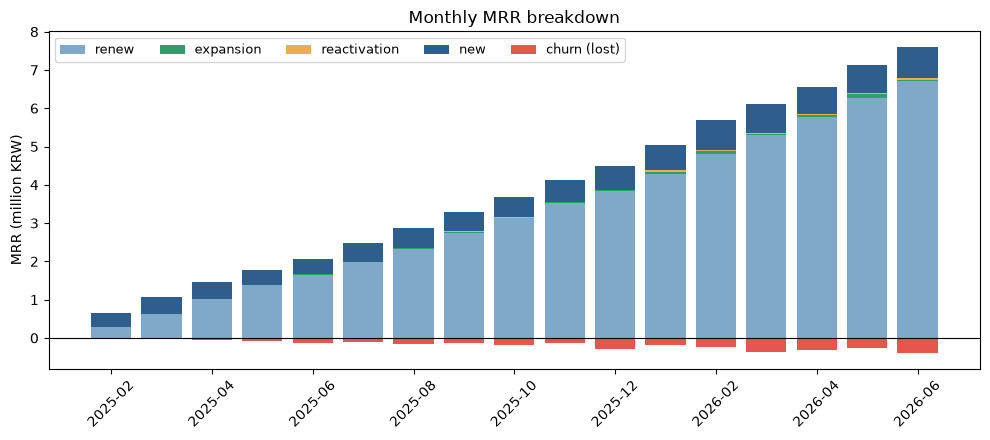

In [12]:
# MRR stacked chart — expansion/reactivation/new on top of renew, churn shown as a negative bar
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(mrr))
bottom = np.zeros(len(mrr))
colors = {"renew_mrr": "#7FA8C9", "expansion_mrr": "#2E9E6B",
          "reactivation_mrr": "#E8B04B", "new_mrr": "#2E5E8C"}
for col, c in colors.items():
    ax.bar(x, mrr[col] / 1e6, bottom=bottom, color=c,
           label=col.replace("_mrr", ""))
    bottom += mrr[col].to_numpy() / 1e6
ax.bar(x, -mrr.churn_mrr / 1e6, color="#E5564E", label="churn (lost)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x[::2]); ax.set_xticklabels(mrr.month[::2], rotation=45)
ax.set_ylabel("MRR (million KRW)")
ax.set_title("Monthly MRR breakdown")
ax.legend(ncol=5, fontsize=9)
plt.tight_layout(); plt.show()

Every month, most of the MRR is carried by renew (repeat payments from existing subscribers), with new stacking the growth on top.
Comparing the red bar extending downward (churn) with new on top tells you whether subscription MRR grew on a net basis.


## 6.3.5. GRR and NRR — checking defense and growth

Let's apply the two formulas from 6.2.4.6 directly to compute GRR and NRR. The `mrr` table built in
6.3.4 already holds everything the calculation needs. Baseline is "existing revenue that was already there last month."

- GRR = (Baseline − churn − contraction) / Baseline
- NRR = (Baseline − churn − contraction + expansion) / Baseline


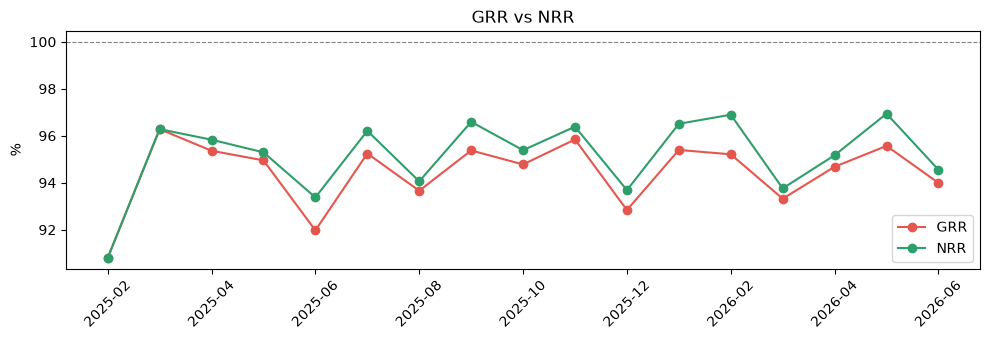

GRR mean 94.4% / NRR mean 95.2% / gap +0.73%p


In [13]:
kept = mrr.baseline_mrr - mrr.churn_mrr - mrr.contraction_mrr
mrr["grr"] = kept / mrr.baseline_mrr
mrr["nrr"] = mrr.grr + mrr.expansion_mrr / mrr.baseline_mrr

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(mrr.month, mrr.grr * 100, marker="o", color="#E5564E", label="GRR")
ax.plot(mrr.month, mrr.nrr * 100, marker="o", color="#2E9E6B", label="NRR")
ax.axhline(100, color="gray", ls="--", lw=0.8)
ax.set_ylabel("%"); ax.set_title("GRR vs NRR")
ax.set_xticks(range(0, len(mrr), 2)); ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout(); plt.show()
gap = (mrr.nrr - mrr.grr).mean()
print(f"GRR mean {mrr.grr.mean():.1%} / NRR mean {mrr.nrr.mean():.1%}"
      f" / gap {gap:+.2%}p")

In this chart GRR mostly holds at 92–96% and NRR at 93–97%, which tells us that recurring revenue
from existing customers is being retained fairly steadily. The fact that NRR sits above GRR in most
periods shows that expansion revenue is coming in through upgrades, extra seats, add-on features,
increased usage, and the like. However, the two metrics rise and fall in step, and NRR never exceeds
100%, so expansion revenue is not fully offsetting the revenue lost to churn and downgrades. Especially
in periods when GRR dips, you need to look into the causes of customer churn and downgrades, and at the
same time analyze which customer groups and usage patterns generate expansion revenue, to raise the
growth potential of the existing customer base.


### [Notebook extra] Don't confuse people with money — decomposing subscriber counts

We repeat the same FULL OUTER JOIN logic in units of "number of subscribers." As emphasized in 6.2.4.7,
**upgrades and downgrades only change revenue (expansion/contraction); they do not change the number of subscribers.**
The query is in `sql/subscriber_counts.sql`.


In [14]:
query = open("sql/subscriber_counts.sql", encoding="utf-8").read()
subs = con.execute(query).df().fillna(0)
subs["month"] = pd.to_datetime(subs["month"]).dt.to_period("M").astype(str)
subs = subs.iloc[1:].reset_index(drop=True)

# Subscriber-count identity: this month's subscribers = last month's subscribers + new + reactivation - churned
prev_subs = subs.subscribers.shift(1)
check = prev_subs + subs.new_subs + subs.reactivation_subs - subs.churned_subs
print("Subscriber-count identity error (excluding the first month):", (subs.subscribers - check).abs().iloc[1:].max())
subs.tail(4)

Subscriber-count identity error (excluding the first month): 0.0


,month,subscribers,new_subs,reactivation_subs,churned_subs
13,2026-03,962,120,5,55
14,2026-04,1040,122,6,50
15,2026-05,1133,130,5,42
16,2026-06,1211,133,7,62


The revenue formula had expansion/contraction terms, but the subscriber-count formula does not.
And yet both identities hold exactly — the data confirms that the formula you need depends on whether
the metric you are aggregating counts "people" or "money."

## 6.3.6. Churn rate and subscription LTV

The logic that originally generated this practice data included an assumption of **5% monthly churn**
(in `generate_data.py`, every subscriber stops renewing with 5% probability each month). If we back out
the churn rate from the churn MRR we decomposed, do we actually get a figure close to 5%? Let's verify
with the code below. (The churn rate formula from 6.2.3)


In [15]:
# The first few months have young cohorts and a small churn denominator, so compute on the stabilized period
stable = mrr[mrr.month >= "2025-04"]
churn_rate = (stable.churn_mrr / stable.baseline_mrr).mean()
print(f"Recovered monthly churn rate  : {churn_rate:.1%}  (assumed value: 5%)")

lifetime_m = 1 / churn_rate
arpu = classified.sales_amount_krw.mean()
print(f"Expected subscription lifetime: {lifetime_m:.1f} months  (≈ 1 / {churn_rate:.3f})")
print(f"Monthly revenue per user (ARPU): {arpu:,.0f} KRW")
print(f"LTV per subscriber (approx.)   : {arpu / churn_rate:,.0f} KRW  (ARPU ÷ churn rate)")

Recovered monthly churn rate  : 5.2%  (assumed value: 5%)
Expected subscription lifetime: 19.2 months  (≈ 1 / 0.052)
Monthly revenue per user (ARPU): 6,237 KRW
LTV per subscriber (approx.)   : 120,030 KRW  (ARPU ÷ churn rate)


The monthly churn probability set when generating the practice data was 5%, and the monthly
revenue-based churn rate recovered by the analysis came out at a similar 5.2%. If we assume the
monthly churn probability is constant, the expected subscription lifetime is the reciprocal of the
churn rate. A subscriber who churns with 5.2% probability each month has an expected lifetime of about
19.2 months. Multiplying this by the average monthly revenue per subscriber (ARPU) approximates the
revenue one subscriber will generate over their subscription, i.e. revenue-based LTV. (Keep in mind
that this is a simple estimate resting on the assumption that churn rate and ARPU stay constant.)

If we lower the churn rate by 1%p, from 5.2% to 4.2%, and assume ARPU stays the same, the expected
subscription lifetime grows from about 19.2 months to 23.8 months, and revenue-based LTV rises by
roughly 24%, from about 120,000 KRW to 148,500 KRW. This simple calculation shows how large a
difference a small change in churn rate can make to a customer's long-term revenue contribution.

Starting from a payment log, we went through user identification, renew/reactivation classification,
MRR decomposition, and GRR/NRR diagnosis all the way to churn rate and LTV. Classifying and linking
individual payment records systematically like this lets you understand a subscription business's
retention and growth potential in far more depth than a simple revenue total.

## Wrapping up

Starting from a single payment log, we reproduced the pipeline from 6.2 as is: user identification →
renew/reactivation classification → MRR decomposition → GRR/NRR diagnosis → subscriber-count
verification → LTV approximation. In practice, trial conversion, prorating annual subscriptions,
refunds, and involuntary churn handling get layered on top — see 6.1, 6.2.4.4, and 6.2.4.5 for the
concepts and caveats of each.

> **[Applying to your data]** If you are using a store report, start by checking whether the amounts are gross (before store fees) or net,
> and by adjusting the 32-day threshold in 6.3.3 to your billing cycle.
